# Granovetter Threshold Model Simulation on Bowdoin Facebook network

## 1. Setup

In [401]:

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import random
from time import time

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

plt.rcParams['figure.figsize'] = (6, 4)
plt.rcParams['axes.grid'] = False
plt.rcParams['figure.dpi'] = 120

print("Packages loaded.")


Packages loaded.


## 2. Configuration (parameters)

In [448]:
# Parameters
B = 22 # Number of initial adopters, if you want to change this value, make a list and adopt code to iterate over the list
NUM_RUNS = 50 # Number of simulation runs for each threshold setting

# Threshold mode, defines how the threshold is set for each node
THRESHOLD_MODE = 'constant' #'beta'

MAX_STEPS = 100

print(f"B={B}, RUNS_PER_SETTING={RUNS_PER_SETTING}")


B=22, RUNS_PER_SETTING=15


## 3. Network Building

In [449]:
# Import dataset
GRAPH_CSV = "/Users/nzuijder/Documents/CBP/model_based_decisionmaking/Week-3-Dynamics-on-Networks/socfb-Bowdoin47.csv"

In [450]:

# This function builds a network out of the Bowdoin Facebook dataset
def build_networks():
    # Load CSV network
    df = pd.read_csv(GRAPH_CSV)
    # Expect columns 'Source' and 'Target' as in the provided CSV
    G = nx.from_pandas_edgelist(df, source='Source', target='Target', create_using=nx.Graph())
    # Remove self-loops if present
    G.remove_edges_from(list(nx.selfloop_edges(G)))
    # Remove components that are not the biggest connected component
    largest_cc = max(nx.connected_components(G), key=len)
    G = G.subgraph(largest_cc).copy()
    print(f"Loaded empirical graph from {GRAPH_CSV}: n={G.number_of_nodes()}, m={G.number_of_edges()}")
    return {'Bowdoin47': G}

# Call the function to generate the network
graphs = build_networks()
{name: (G.number_of_nodes(), G.number_of_edges()) for name, G in graphs.items()}


Loaded empirical graph from /Users/nzuijder/Documents/CBP/model_based_decisionmaking/Week-3-Dynamics-on-Networks/socfb-Bowdoin47.csv: n=2250, m=84386


{'Bowdoin47': (2250, 84386)}

## 4. Threshold Distributions

In [460]:

# This function draws threshold values for each node in the graph G
# The threshold mode determines how the threshold values are generated
# Each node samples a threshold value from a specified distribution (defined by mode)
# The phi_mean and phi_std parameters are used to control the mean and standard deviation of the distribution
def draw_thresholds(G, mode='constant', phi_mean=0.100, phi_std=0.0):
    if mode == 'beta':
        # create lists of a and b parameters to iterate through beta distributions with different shapes
        a, b = 2, 3.25
        return {n: np.random.beta(a, b) for n in G}
    if mode == 'constant':
        return {n: float(phi_mean) for n in G}
    raise ValueError(f"Unknown threshold mode: {mode}")


## 5. Threshold Dynamics

In [461]:

# This function simulates the threshold dynamics on a graph G
# The function takes as input the graph G, a list of seed nodes (seeds), a dictionary of threshold values (thresholds), and the maximum number of steps (max_steps)
# The function returns a dictionary of adopted nodes (adopted) and a numpy array of the fraction of adopted nodes over time (history)
def threshold_dynamics(G, seeds, thresholds, max_steps=200):
    adopted = {n: 0 for n in G}
    for s in seeds:
        adopted[s] = 1 # initially, all seed nodes are adopted

    history = [sum(adopted.values()) / len(G)] #the history will store the fraction of adopted nodes over time, initially it is the fraction of adopted seed nodes

    for _ in range(max_steps): # iterate max_steps times
        new_adopted = adopted.copy()
        changed = False
        for i in G: # iterate over all nodes i in the graph G
            if adopted[i] == 0: # if node i is not adopted yet
                neigh = list(G.neighbors(i))
                if not neigh: # if node i has no neighbors, skip it
                    continue
                frac = sum(adopted[j] for j in neigh) / len(neigh) # calculate the fraction of adopted neighbors of node i
                if frac >= thresholds[i]: # if the fraction of adopted neighbors is greater than or equal to the threshold of node i
                    new_adopted[i] = 1 # adopt node i
                    changed = True
        #-- end of one iteration

        # update the adopted nodes after checking all nodes
        adopted = new_adopted
        history.append(sum(adopted.values()) / len(G)) #add the total adopted this timestep to the history
        #if not changed:
            #break # if no node is adopted in this iteration, break the loop (no more adoptions so we can stop)

    return adopted, np.array(history)


## 6. Measurement Utilities

In [462]:

def final_adoption_fraction(adopted):
    return sum(adopted.values()) / len(adopted)

# function to calculate the time to reach a target fraction of adopted nodes
def time_to_fraction(history, target=0.5):
    idx = np.where(history >= target)[0]
    return float(idx[0]) if len(idx) else np.nan


## 7. Seeding Strategies — Heuristics

In [463]:

def random_seeds(G, B):
    return random.sample(list(G.nodes()), B)

def high_degree_seeds(G, B):
    """
    Select the top-B nodes with the highest degree in graph G.
    """
    # Get all (node, degree) pairs
    degree_list = list(G.degree())

    # Sort nodes by degree in descending order
    sorted_by_degree = sorted(degree_list, key=lambda x: x[1], reverse=True)

    # Take the top-B entries
    top_B = sorted_by_degree[:B]

    # Extract only the node IDs
    result = []
    for n, d in top_B:
        result.append(n)

    return result


# This code below does the same as for degree. It uses a list comprehension and a lambda function.
# The lambda function takes a tuple x = (n, b) and returns the second element (b), which is the betweenness centrality of node n.]
# sorted(bc.items(), key=lambda x: x[1], reverse=True) sorts the items of the dictionary bc.items() by the value of the betweenness centrality (x[1]) in descending order. (Highest first)
# [:B] takes the first B entries from the sorted list, which are the nodes with the highest betweenness centrality.
def betweenness_seeds(G, B):
    bc = nx.betweenness_centrality(G) #returns a dictionary that maps each node to its betweenness centrality. {n_1: bc(n_1), n_2: bc(n_2), ...}
    return [n for n, _ in sorted(bc.items(), key=lambda x: x[1], reverse=True)[:B]]

## saving betweenness csv
Since betweenness measures in the network are not variable, and it takes some time to compute, I calculate it once, save it in a CSV, and use it in the experiment

In [441]:
# To save betweenness measures of the network:
import csv

def save_betweenness_to_csv(G, filename="betweenness_centrality.csv"):
    """
    Calculate and save the betweenness centrality of nodes in graph G to a CSV file.
    Parameters:
        G (networkx.Graph): The input graph.
        filename (str): The name of the CSV file to save the data.
    """
    # Calculate betweenness centrality
    bc = nx.betweenness_centrality(G)
    
    # Save to CSV
    with open(filename, mode='w', newline='') as file:
        writer = csv.writer(file)
        writer.writerow(["Node", "Betweenness Centrality"])  # Header
        for node, centrality in bc.items():
            writer.writerow([node, centrality])
    
    print(f"Betweenness centrality saved to {filename}")

In [442]:
def betweenness_seeds_from_csv(csv_path, B):
    """
    Select B nodes with the highest betweenness centrality from a CSV file.
    Parameters:
        csv_path (str): Path to the CSV file containing betweenness centrality values.
        B (int): Number of seed nodes to select.
    Returns:
        list: A list of B nodes with the highest betweenness centrality.
    """
    # Load the CSV file
    df = pd.read_csv(csv_path)
    
    # Sort nodes by betweenness centrality in descending order
    sorted_nodes = df.sort_values(by="Betweenness Centrality", ascending=False)
    
    # Select the top B nodes
    top_nodes = sorted_nodes["Node"].head(B).tolist()
    
    return top_nodes

## 8. Spaghetti plot generation
For each threshold setting, I changed the beta distribution parameters to create the subplots in figure 3 and played around with the number of runs required to reduce stochastic uncertainty. Additionally, while exploring subplots, I quoted out "if not changed:
            break" under "5. threshold dynamics" because this significantly sped up compute time. For the final subplots, I unquoted this code so the lines in the plots would not end abruptly

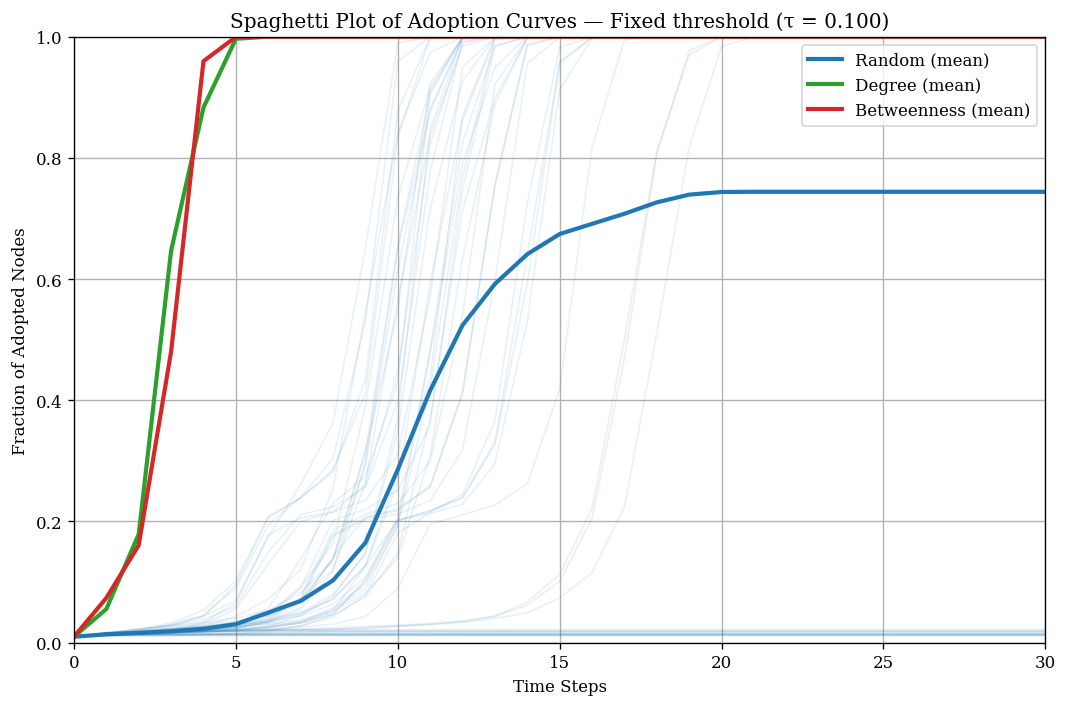

In [464]:
import matplotlib as mpl
mpl.rcParams['text.usetex'] = False
import numpy as np

# Assign a fixed color to each strategy
strategy_colors = {
    'Random': 'tab:blue',
    'Degree': 'tab:green',
    'Betweenness': 'tab:red'
}

for name, G in graphs.items():

    strategies = {
        'Random': lambda: random_seeds(G, B),
        'Degree': lambda: high_degree_seeds(G, B),
        'Betweenness': lambda: betweenness_seeds_from_csv("betweenness_centrality.csv", B),
    }

    plt.figure(figsize=(9, 6))

    for strat_name, seed_fn in strategies.items(): #for each seed selection strategy
        color = strategy_colors[strat_name] #get the seed set for the current strategy
        all_histories = []

        for _ in range(NUM_RUNS):
            #Each node draws a threshold from the draw_threshold function, using a mode specified in that function
            thresholds = draw_thresholds(G, mode=THRESHOLD_MODE) 
            #For each seed selection strategy
            seeds = seed_fn()
            #Apply the update rule on the loaded network using the seeds for a max of MAX_STEPS
            _, history = threshold_dynamics(G, seeds, thresholds, max_steps=MAX_STEPS) 

            all_histories.append(history)

            # spaghetti lines in same color, translucent
            plt.plot(history, alpha=0.1, linewidth=1.0, color=color)

        # Compute and plot the mean curve
        max_len = max(len(h) for h in all_histories)
        padded = np.array([
            np.pad(h, (0, max_len - len(h)), constant_values=h[-1]) 
            for h in all_histories
        ])
        mean_curve = padded.mean(axis=0)

        plt.plot(mean_curve, color=color, linewidth=2.5, label=f"{strat_name} (mean)")

    plt.title('Spaghetti Plot of Adoption Curves — Fixed threshold (τ = 0.100)')
    plt.xlabel('Time Steps')
    plt.ylabel('Fraction of Adopted Nodes')
    plt.xlim(0, 30)
    plt.ylim(0, 1)
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()

## 9. Create Beta distribution plots
I created these plots to give an idea/visualize the range of adoption threshold values the nodes are drawing from in the beta distribution threshold mode

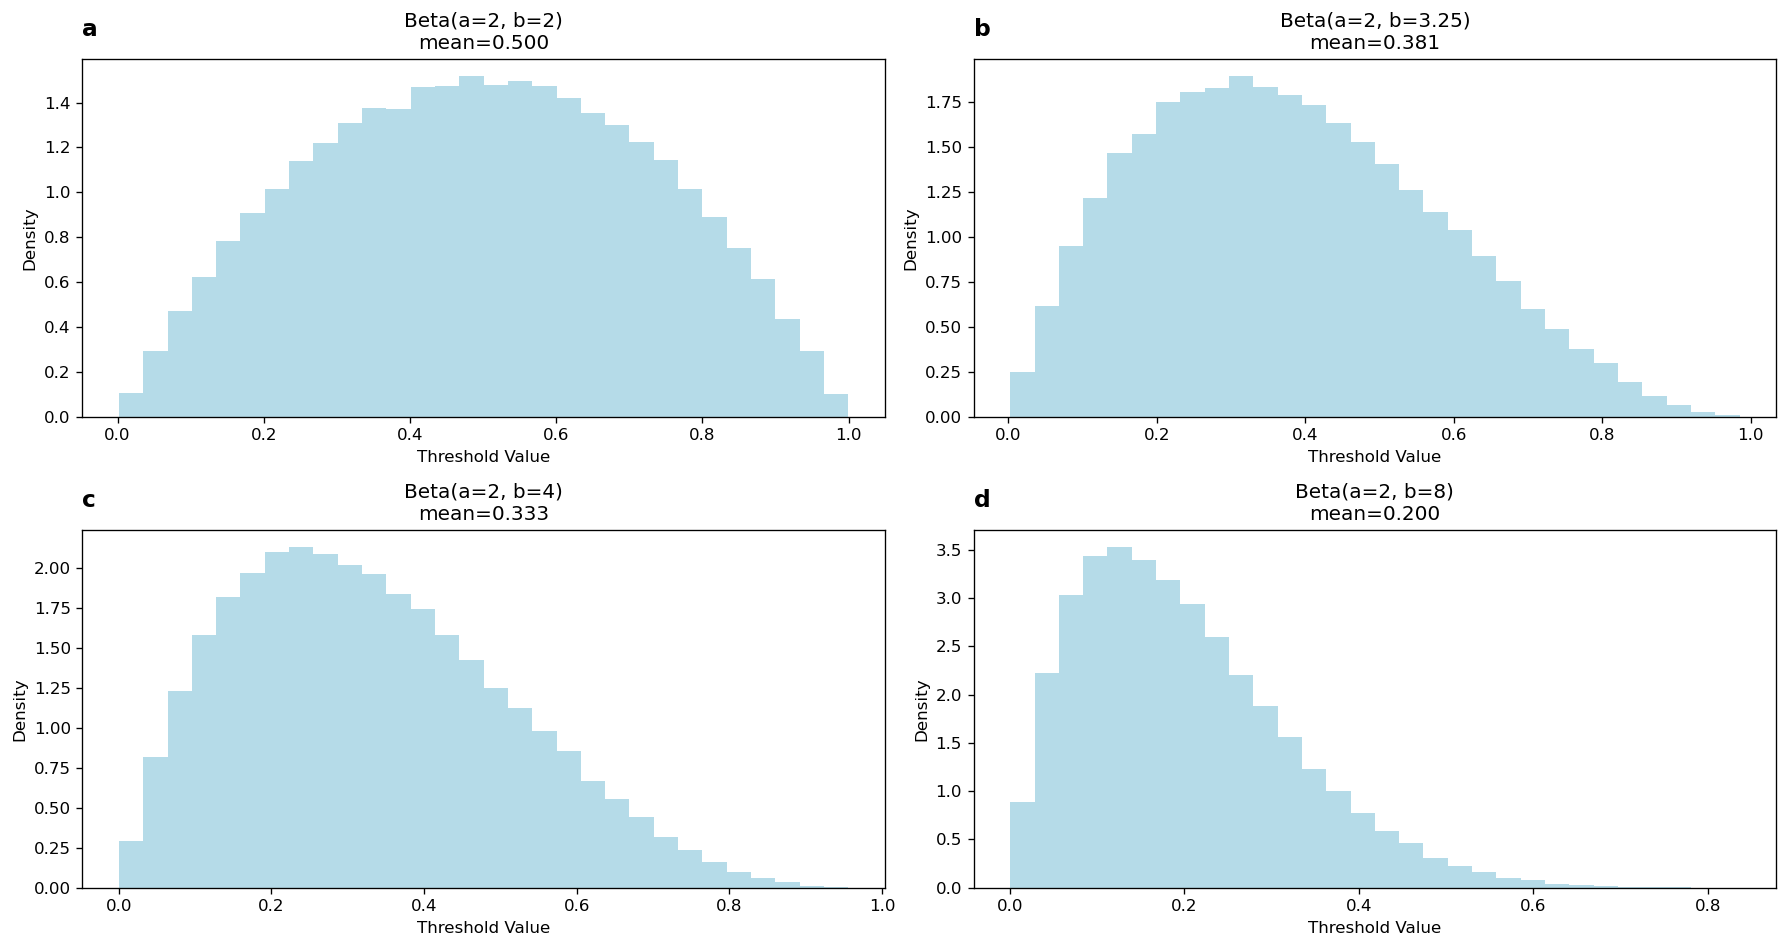

In [36]:
import matplotlib.pyplot as plt
import numpy as np

def plot_beta_threshold_subplots(param_pairs, num_samples=100000):
    fig, axes = plt.subplots(2, 2, figsize=(15, 8))
    axes = axes.flatten()
    label= ['a','b','c','d']

    for ax, (a, b), label in zip(axes, param_pairs, label):
        samples = np.random.beta(a, b, num_samples)
        ax.hist(samples, bins=30, density=True, alpha=0.9, color='lightblue')
        ax.set_title(f'Beta(a={a}, b={b})\nmean={samples.mean():.3f}')
        ax.set_xlabel('Threshold Value')
        ax.set_ylabel('Density')
        ax.text(
            0, 1.05,               # x=0 (left), y=1.05 (just above the axes)
            label,                 
            transform=ax.transAxes, # coordinates relative to axes
            fontsize=14, fontweight='bold',
            ha='left', va='bottom'
        )

    plt.tight_layout()
    plt.show()


# List of (a, b) parameter pairs
params = [
    (2, 2),
    (2, 3.25),
    (2, 4),
    (2, 8),
]

plot_beta_threshold_subplots(params)


## 10. Experiment Runner
I kept this function and the "run the experiment" code to create a dataframe in case I wanted to check the dataframe for a specific experiment

In [ ]:

def run_experiments(ensembles=5, runs_per_setting=10, threshold_mode='beta',
                    phi_mean=0.333, phi_std=0, B=7, max_steps=200):
    import numpy as _np
    import pandas as _pd
    from time import time as _time
    results = []
    t0 = _time()
    for e in range(ensembles): # for each ensemble
        print("starting ensemble ", e)
        graphs = build_networks() # build the networks
        print('built graph')
        for name, G in graphs.items(): # for the network
            thresholds = draw_thresholds(G, mode=threshold_mode, phi_mean=phi_mean, phi_std=phi_std) # draw the thresholds for each node from the distribution specified by threshold_mode

            print('calced threshold')

            strategies = { #dictionary of seed selection strategies, the value is a (lamba) function that returns the seed set for the current strategy
                'Random': lambda: random_seeds(G, B),
                'Degree': lambda: high_degree_seeds(G, B),
                'Betweenness': lambda: betweenness_seeds_from_csv("betweenness_centrality.csv", B),
                #'Greedy': lambda: greedy_celf(G, B, thresholds, R=greedy_R, max_steps=max_steps, verbose=False)
            }

            print('strategy done')

            for strat, seed_fn in strategies.items(): # for each seed selection strategy
                seeds = seed_fn() # get the seed set for the current strategy
                final_sizes, t50_list = [], []
                for _ in range(runs_per_setting):
                    adopted, history = threshold_dynamics(G, seeds, thresholds, max_steps=max_steps)
                    final_sizes.append(final_adoption_fraction(adopted))
                    t50_list.append(time_to_fraction(history, target=0.5))
                results.append({
                    'Ensemble': e,
                    'Network': name,
                    'Strategy': strat,
                    'FinalAdoption': float(_np.mean(final_sizes)),
                    'CascadeProb': float(_np.mean(_np.array(final_sizes) >= 0.5)),
                    'Time50': float(_np.nanmean(t50_list)),
                    'Efficiency': float(_np.mean(final_sizes) / B),
                    'Seeds': seeds
                })
            print('done with appending')
    t1 = _time()
    print(f"Completed {ensembles} ensembles x 3 networks x 5 strategies in {t1 - t0:.1f}s")
    return _pd.DataFrame(results)

## 11. Run the full experiment

In [ ]:

df_results = run_experiments(
    runs_per_setting=NUM_RUNS,
    threshold_mode=THRESHOLD_MODE,
    B=B,
    max_steps=MAX_STEPS,
)
df_results.head()


starting ensemble  0
Loaded empirical graph from /Users/nzuijder/Documents/CBP/model_based_decisionmaking/Week-3-Dynamics-on-Networks/socfb-Bowdoin47.csv: n=2250, m=84386
built graph
calced threshold
strategy done


/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_75938/57505562.py:39: RuntimeWarning: Mean of empty slice
  'Time50': float(_np.nanmean(t50_list)),


done with appending
starting ensemble  1
Loaded empirical graph from /Users/nzuijder/Documents/CBP/model_based_decisionmaking/Week-3-Dynamics-on-Networks/socfb-Bowdoin47.csv: n=2250, m=84386
built graph
calced threshold
strategy done


/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_75938/57505562.py:39: RuntimeWarning: Mean of empty slice
  'Time50': float(_np.nanmean(t50_list)),
/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_75938/57505562.py:39: RuntimeWarning: Mean of empty slice
  'Time50': float(_np.nanmean(t50_list)),


done with appending
starting ensemble  2
Loaded empirical graph from /Users/nzuijder/Documents/CBP/model_based_decisionmaking/Week-3-Dynamics-on-Networks/socfb-Bowdoin47.csv: n=2250, m=84386
built graph
calced threshold
strategy done


...

/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_75938/57505562.py:39: RuntimeWarning: Mean of empty slice
  'Time50': float(_np.nanmean(t50_list)),


done with appending
starting ensemble  4
Loaded empirical graph from /Users/nzuijder/Documents/CBP/model_based_decisionmaking/Week-3-Dynamics-on-Networks/socfb-Bowdoin47.csv: n=2250, m=84386
built graph
calced threshold
strategy done


/var/folders/fx/w8lwd2d95938qx99fyfp5kw00000gp/T/ipykernel_75938/57505562.py:39: RuntimeWarning: Mean of empty slice
  'Time50': float(_np.nanmean(t50_list)),


done with appending
Completed 5 ensembles x 3 networks x 5 strategies in 20.9s


,Ensemble,Network,Strategy,FinalAdoption,CascadeProb,Time50,Efficiency,Seeds
0,0,Bowdoin47,Random,0.012889,0.0,NaN,0.000586,"[114, 282, 1368, 275, 581, 1955, 2186, 281, 38..."
1,0,Bowdoin47,Degree,1.000000,1.0,13.0,0.045455,"[1819, 1029, 1800, 406, 282, 1803, 1046, 938, ..."
2,0,Bowdoin47,Betweenness,1.000000,1.0,14.0,0.045455,"[1819, 1800, 1029, 1347, 1046, 194, 406, 723, ..."
3,1,Bowdoin47,Random,0.011556,0.0,NaN,0.000525,"[855, 22, 200, 254, 318, 1127, 1587, 1299, 972..."
4,1,Bowdoin47,Degree,1.000000,1.0,23.0,0.045455,"[1819, 1029, 1800, 406, 282, 1803, 1046, 938, ..."


## 12. Save results to CSV
I ended up not saving CSV files for simulation runs because I did not yet fully figure out how to append all the "runs per setting" to the dataframe. For the scope of this assignment, I thought that should be ok.

In [ ]:

csv_path = "/Users/nzuijder/Documents/CBP/model_based_decisionmaking/Week-3-Dynamics-on-Networks/granovetter_experiment_results3.csv"
df_results.to_csv(csv_path, index=False)
print("Saved:", csv_path)


Saved: /Users/nzuijder/Documents/CBP/model_based_decisionmaking/Week-3-Dynamics-on-Networks/granovetter_experiment_results3.csv


I am still figuring out how to code more efficiently. So, for future assignments, I am hoping to make a dataframe and append inputs and outputs each time I run the experiment so can save my progress more efficiently.